# 04 · Deep saliency model
ResNet18 + FPN-lite decoder predicting gaze heatmaps from screenshots (task-agnostic baseline C).

> **Prerequisite:** `python -m gazegrounded.cli run-all` (synthetic demo).
>
> All logic lives in `src/gazegrounded/`; this notebook only calls it. With the synthetic config every number is **SYNTHETIC DEMO DATA — NOT RESEARCH EVIDENCE**.

Five synthetic screenshots cannot train a saliency model; this notebook demonstrates the code path. Train on UEyes for meaningful results (`configs/ueyes.yaml`).

In [1]:
from pathlib import Path
import os
# Run from the repository root so relative config paths resolve.
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir("..")
import numpy as np
import pandas as pd
from gazegrounded.config import load_config
from gazegrounded.data.loader import load_processed
from gazegrounded.utils import SYNTHETIC_BANNER
cfg = load_config("configs/synthetic.yaml")  # switch to configs/experiment.yaml for real data
ds = load_processed(cfg)
print(SYNTHETIC_BANNER if ds.is_synthetic else "Real data:", cfg.data.source)

SYNTHETIC DEMO DATA — NOT RESEARCH EVIDENCE synthetic


In [2]:
from gazegrounded.vision.saliency_model import SaliencyNet
import torch
model = SaliencyNet(pretrained=False)
print(f'{sum(p.numel() for p in model.parameters())/1e6:.1f} M parameters')
with torch.no_grad():
    print(model(torch.zeros(1, 3, 160, 256)).shape)

11.3 M parameters
torch.Size([1, 1, 160, 256])


In [3]:
from gazegrounded.pipeline import load_fixations
from gazegrounded.vision.saliency_dataset import build_items, split_items
items = build_items(ds, load_fixations(cfg))
train, val = split_items(items, cfg.saliency.val_fraction, cfg.seed)
print('train:', [i.item_id for i in train]); print('val  :', [i.item_id for i in val])

train: ['shop_checkout_clean', 'shop_checkout_friction', 'bank_cards_clean', 'bank_cards_friction']
val  : ['travel_booking']


In [4]:
from gazegrounded.utils import latest_run_dir
import json
run = latest_run_dir(cfg.experiments_dir(), 'saliency')
print(run.name); print(json.dumps(json.loads((run/'metrics.json').read_text()), indent=1))
pd.read_csv(run/'history.csv').round(3)

20261013-161054-saliency
{
 "best_epoch": 8,
 "best_val_loss": 1.0201973915100098,
 "device": "mps",
 "data_kind": "synthetic_demo",
 "cc_mean": 0.33699475959067277,
 "sim_mean": 0.5295979021687081,
 "kl_mean": 0.7720240523718549,
 "jsd_mean": 0.27014277804959164,
 "nss_mean": 0.56437774674678,
 "n_items": 1,
 "note": "synthetic demo: software test only"
}


,epoch,train_loss,val_loss,seconds,val_cc_mean,val_sim_mean,val_kl_mean,val_jsd_mean,val_nss_mean
0,1,1.227,1.236,0.915,0.217,0.535,0.789,0.268,0.346
1,2,0.712,1.212,0.249,0.244,0.535,0.780,0.267,0.400
2,3,0.551,1.171,0.227,0.253,0.531,0.787,0.270,0.425
3,4,0.453,1.129,0.099,0.268,0.529,0.788,0.272,0.441
4,5,0.404,1.079,0.096,0.320,0.530,0.775,0.270,0.531
5,6,0.373,1.064,0.099,0.315,0.528,0.780,0.272,0.521
6,7,0.351,1.043,0.093,0.326,0.528,0.776,0.272,0.540
7,8,0.334,1.020,0.093,0.337,0.530,0.772,0.270,0.564


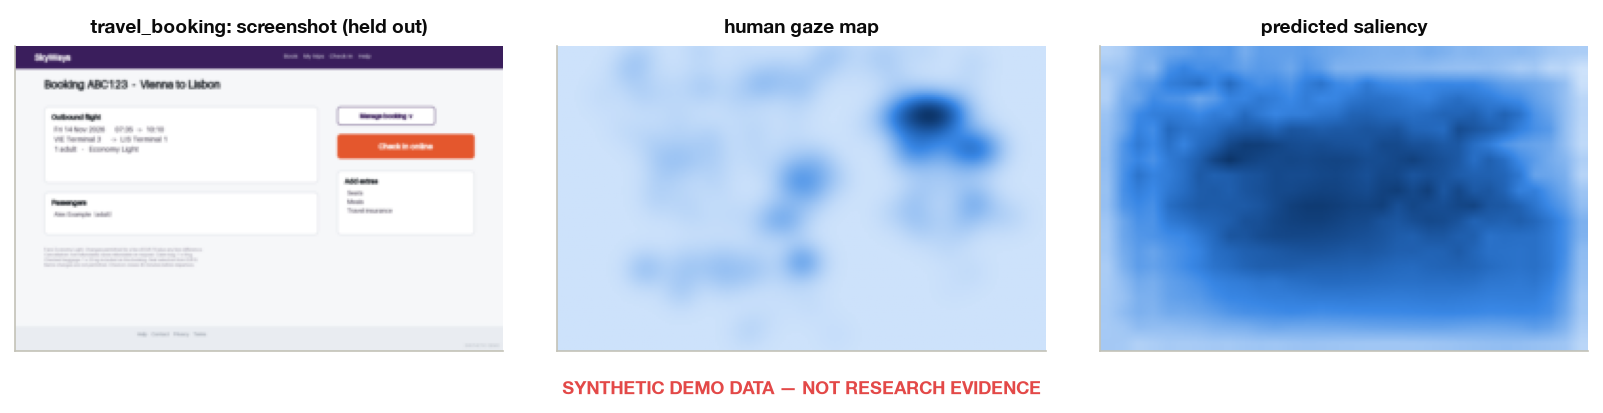

In [5]:
from IPython.display import Image as Img
Img(str(run/'val_predictions.png'))